# Projeto AM 2026-2 — Questão 2 (itens a, b, c, d)
**Base:** *spambase* (4601 e-mails × 57 variáveis) em duas versões da variável resposta: (i) rótulo original (spam / não-spam) e (ii) partição de objetos com $K^*$ clusters obtida pelo double k-means na Questão 1 ($K^*=2$, clusters de 4567 e 34 e-mails).

**Classificadores:** bayesiano gaussiano, bayesiano k-vizinhos, bayesiano com janela de Parzen (kernel produto gaussiano), regressão logística e voto majoritário dos quatro primeiros.

| Item | Conteúdo |
|---|---|
| 2a | Validação cruzada estratificada 30 × 10-folds; hiperparâmetros por CV 5-folds estratificada nos 9 folds de aprendizagem |
| 2b | Estimativa pontual e IC 95% (taxa de erro, precisão, cobertura, F-measure) |
| 2c | Teste de Friedman e pós-teste de Nemenyi para cada métrica |
| 2d | Curvas de aprendizagem (F-measure) no treino e no teste, de 5% a 95% de treino |

**Como executar.** Por padrão o notebook **carrega os resultados já calculados** em `results/` (arquivos `.npz`). Se eles não existirem, ou com `Q2_RUN_FULL=1`, os experimentos são executados (2a ≈ 15 min por versão, 2d ≈ 5 min por versão, em 2 núcleos). Variáveis de ambiente: `Q2_RUN_FULL`, `Q2_REPS` (repetições de 10-fold na 2a, padrão 30), `Q2_REPS_2D` (repetições por fração na 2d, padrão 10), `Q2_JOBS`, `Q2_RESULTS`.

In [ ]:
import os, re, time, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from scipy.spatial.distance import cdist
from scipy.special import logsumexp
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

# --- parametros de execucao (ver texto acima) ---
RUN_FULL   = os.environ.get("Q2_RUN_FULL", "0") == "1"
N_REPS_2A  = int(os.environ.get("Q2_REPS", "30"))
N_REPS_2D  = int(os.environ.get("Q2_REPS_2D", "10"))
N_JOBS     = int(os.environ.get("Q2_JOBS", "2"))
RESULTS    = Path(os.environ.get("Q2_RESULTS", "results")); RESULTS.mkdir(exist_ok=True)
DATA       = next(p for p in (Path("spambase.data"), Path("../spambase.data")) if p.exists())
LABELS     = Path("labels_kstar.csv")
print("dados:", DATA, "| executar tudo:", RUN_FULL, "| resultados em:", RESULTS)

dados: spambase.data | executar tudo: False | resultados em: results


## 0. Dados e as duas versões da variável resposta
A versão 2 usa a partição de objetos com $K^*$ clusters do **melhor resultado do double k-means** (Questão 1: dados padronizados por escore $z$, 100 inicializações por par $(K,H)$, $K^*=\arg\max Sil$). Se `labels_kstar.csv` não existir, ele é regerado abaixo com a **mesma implementação e as mesmas sementes** do notebook da Questão 1.

In [ ]:
def _init_labels(n, n_clusters, rng):
    labels = np.empty(n, dtype=np.int64); order = rng.permutation(n)
    labels[order[:n_clusters]] = np.arange(n_clusters)
    if n > n_clusters:
        labels[order[n_clusters:]] = rng.integers(0, n_clusters, size=n - n_clusters)
    return labels
def _prototypes(X, u, v, K, H, prev_G=None):
    U = np.eye(K)[u]; V = np.eye(H)[v]
    bs = U.T @ X @ V; nk, nh = U.sum(0), V.sum(0)
    G = bs / np.outer(np.where(nk == 0, 1.0, nk), np.where(nh == 0, 1.0, nh))
    if prev_G is not None:
        if (nk == 0).any(): G[nk == 0, :] = prev_G[nk == 0, :]
        if (nh == 0).any(): G[:, nh == 0] = prev_G[:, nh == 0]
    return G
def _assign_objects(X, G, v):
    Gh = G[:, v]; d = np.sum(X**2, 1, keepdims=True) - 2*X@Gh.T + np.sum(Gh**2, 1, keepdims=True).T
    return d.argmin(1)
def _assign_variables(X, G, u):
    Gh = G[u, :]; d = np.sum(X**2, 0, keepdims=True).T - 2*X.T@Gh + np.sum(Gh**2, 0, keepdims=True)
    return d.argmin(1)
def _objective(X, G, u, v): return float(np.sum((X - G[u][:, v])**2))
def fit(X, K, H, seed, max_iter=100):
    rng = np.random.default_rng(seed); N, P = X.shape
    u = _init_labels(N, K, rng); v = _init_labels(P, H, rng)
    G = _prototypes(X, u, v, K, H)
    for it in range(1, max_iter+1):
        G = _prototypes(X, u, v, K, H, prev_G=G)
        un = _assign_objects(X, G, v); vn = _assign_variables(X, G, un)
        same = np.array_equal(un, u) and np.array_equal(vn, v); u, v = un, vn
        if same: break
    G = _prototypes(X, u, v, K, H, prev_G=G)
    return _objective(X, G, u, v), u, v, G

In [ ]:
def gerar_labels_kstar(X, y):
    rows, best = [], {}
    for K in (2, 3, 4):
        for H in range(1, K + 1):
            seed = 42 * 1000 + K * 10 + H
            res = min((fit(X, K, H, seed + i) for i in range(100)), key=lambda r: r[0])
            best[(K, H)] = res
            rows.append((K, H, res[0], silhouette_score(X, res[1]), adjusted_rand_score(y, res[1])))
    t = pd.DataFrame(rows, columns=["K", "H", "W", "Sil", "ARI"])
    i = t.Sil.idxmax()
    return best[(int(t.K[i]), int(t.H[i]))][1], t

df = pd.read_csv(DATA, header=None)
X = df.iloc[:, :57].to_numpy(float)
y_orig = df.iloc[:, 57].to_numpy(int)
if LABELS.exists():
    y_kstar = np.loadtxt(LABELS, dtype=int)
else:
    y_kstar, tab_q1 = gerar_labels_kstar(StandardScaler().fit_transform(X), y_orig)
    np.savetxt(LABELS, y_kstar, fmt="%d"); display(tab_q1.round(4))
VERSIONS_Y = {"orig": y_orig, "kstar": y_kstar}
print("original:", np.bincount(y_orig), "| K*:", np.bincount(y_kstar))

,K,H,W,Sil,ARI
0,2,1,256513.7482,0.2961,0.0686
1,2,2,244486.6983,0.6596,-0.0049
2,3,1,254414.0129,0.2515,0.0784
3,3,2,239373.6577,0.2454,0.1984
4,3,3,234585.8664,0.1409,0.3854
5,4,1,253278.6795,0.0484,0.0916
6,4,2,233358.7022,0.2428,0.1493
7,4,3,228516.4437,0.1620,0.2744
8,4,4,227261.6509,0.1576,0.2451


original: [2788 1813] | K*: [4567   34]


## 2a. Classificadores e protocolo de avaliação
**Organização dos experimentos.** Para cada versão, `RepeatedStratifiedKFold(10 folds × 30 repetições)` gera 300 pares (aprendizagem com 9 folds, teste com 1 fold). Em cada par: (1) a escala (z-score) é ajustada **só** no conjunto de aprendizagem; (2) os hiperparâmetros são escolhidos por CV 5-folds estratificada **dentro** dos 9 folds de aprendizagem (macro-F pooled como critério); (3) o modelo é re-treinado com os 9 folds e os hiperparâmetros escolhidos e avaliado no fold de teste. As mesmas 300 partições são usadas pelos cinco classificadores. Guarda-se a matriz de confusão de cada fold, da qual saem todas as métricas.

**Detalhes dos classificadores.**
- *Gaussiano:* priori e parâmetros por máxima verossimilhança. Com $n_i < d$ a covariância de MV é singular (classe minoritária da versão 2); usa-se $\hat\Sigma_i+\lambda I$ com $\lambda$ por CV (grade começando em $10^{-8}$, ≈ MV).
- *k-vizinhos:* $P(\omega_i|x)=k_i/k$; $k$ e distância (Euclidiana, City-block, Chebyshev) por CV.
- *Parzen:* $p(x|\omega_i)=\frac1{n_i}\sum_j\prod_l \frac1h\phi\big(\frac{x_l-x_{jl}}h\big)$, janela $h$ única por CV; cálculo em escala logarítmica.
- *Regressão logística:* penalização $\ell_2$, $C$ por CV.
- *Voto majoritário:* votos duros dos quatro modelos; empate (2–2) resolvido pela média das posterioris.

In [ ]:
# Grades de hiper-parametros (iguais nas duas versoes)
LAMBDAS = [1e-8, 1e-6, 1e-4, 1e-2, 1e-1, 1.0]            # gaussiano: cov = Sigma_MV + lambda*I
K_LIST = [1, 3, 5, 7, 9, 11, 15, 21, 31]            # k-vizinhos
DISTS = ["euclidean", "cityblock", "chebyshev"]     # k-vizinhos
H_LIST = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0]             # Parzen (dados padronizados)
C_LIST = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]              # regressao logistica
CLF = ["gauss", "knn", "parzen", "lr", "vote"]
SEL_METRIC = "macroF"                               # criterio de selecao na CV interna
SEED = 2026

In [ ]:
# Metricas
def conf_matrix(y, p, c):
    cm = np.zeros((c, c), dtype=np.int64)
    np.add.at(cm, (y, p), 1)
    return cm


def macro_f(y, p, c):
    cm = conf_matrix(y, p, c)
    tp = np.diag(cm).astype(float)
    prec = np.divide(tp, cm.sum(0), out=np.zeros(c), where=cm.sum(0) > 0)
    rec = np.divide(tp, cm.sum(1), out=np.zeros(c), where=cm.sum(1) > 0)
    f = np.divide(2 * prec * rec, prec + rec, out=np.zeros(c), where=(prec + rec) > 0)
    return f.mean()

In [ ]:
# Classificadores: cada um devolve posterioris para toda a grade de hiper-parametros
def _norm_post(logp):
    return np.exp(logp - logsumexp(logp, axis=1, keepdims=True))


def gauss_grid(Xtr, ytr, Xte, c, lams=None):
    """Posterioris do bayesiano gaussiano para cada lambda. lambda=0 seria a MV pura;
    com n_i < d a MV e singular, por isso usa-se Sigma_MV + lambda*I (lambda pequeno ~ MV)."""
    d = Xtr.shape[1]
    n = len(ytr)
    Z, W, logpri = [], [], np.log(np.bincount(ytr, minlength=c) / n)
    for i in range(c):
        Xi = Xtr[ytr == i]
        mu = Xi.mean(0)
        S = (Xi - mu).T @ (Xi - mu) / len(Xi)          # estimativa de MV (divisor n_i)
        w, Q = np.linalg.eigh(S)
        W.append(np.clip(w, 0, None))
        Z.append(((Xte - mu) @ Q) ** 2)
    out = []
    for lam in (LAMBDAS if lams is None else lams):
        logp = np.empty((len(Xte), c))
        for i in range(c):
            ev = W[i] + lam
            logp[:, i] = -0.5 * (Z[i] / ev).sum(1) - 0.5 * np.log(ev).sum() \
                - 0.5 * d * np.log(2 * np.pi) + logpri[i]
        out.append(_norm_post(logp))
    return out


def knn_grid(Xtr, ytr, Xte, c, d2=None, dists=None, ks=None):
    """Posterioris P(w_i|x)=k_i/k para cada (distancia, k). d2: dist. euclidiana^2 ja calculada."""
    dists = DISTS if dists is None else dists
    ks = K_LIST if ks is None else ks
    kmax = max(ks)
    onehot = np.eye(c)[ytr]
    out = []
    for dist in dists:
        if dist == "euclidean":
            D = np.sqrt(d2 if d2 is not None else cdist(Xte, Xtr, "sqeuclidean"))
        else:
            D = cdist(Xte, Xtr, dist)
        idx = np.argpartition(D, kmax - 1, axis=1)[:, :kmax]
        order = np.argsort(np.take_along_axis(D, idx, 1), axis=1, kind="stable")
        idx = np.take_along_axis(idx, order, 1)
        cum = np.cumsum(onehot[idx], axis=1)            # n x kmax x c
        for k in ks:
            out.append(cum[:, k - 1, :] / k)
    return out


def parzen_grid(Xtr, ytr, Xte, c, d2=None, hs=None):
    """Posterioris com janela de Parzen, kernel produto de gaussianas univariadas:
    p(x|w_i) = (1/n_i) sum_j prod_l (1/h) phi((x_l - x_jl)/h) = (1/n_i) sum_j (2pi)^(-d/2) h^(-d) exp(-||x-x_j||^2/2h^2)."""
    d = Xtr.shape[1]
    D2 = d2 if d2 is not None else cdist(Xte, Xtr, "sqeuclidean")
    n = len(ytr)
    ni = np.bincount(ytr, minlength=c)
    logpri = np.log(ni / n)
    cols = [np.where(ytr == i)[0] for i in range(c)]
    out = []
    for h in (H_LIST if hs is None else hs):
        logp = np.empty((len(Xte), c))
        for i in range(c):
            logp[:, i] = logsumexp(-D2[:, cols[i]] / (2 * h * h), axis=1) - np.log(ni[i]) \
                - d * np.log(h) - 0.5 * d * np.log(2 * np.pi) + logpri[i]
        out.append(_norm_post(logp))
    return out


def lr_grid(Xtr, ytr, Xte, c, Cs=None):
    out = []
    for C in (C_LIST if Cs is None else Cs):
        m = LogisticRegression(C=C, max_iter=1000).fit(Xtr, ytr)
        P = np.zeros((len(Xte), c))
        P[:, m.classes_] = m.predict_proba(Xte)
        out.append(P)
    return out


def all_grids(Xtr, ytr, Xte, c, sel=None):
    """Escala (ajustada so no treino) e posterioris de todos os modelos para toda a grade.
    sel (opcional): dict modelo -> dict de hiper-parametros escolhidos; entao so esse ponto da grade e avaliado."""
    sc = StandardScaler().fit(Xtr)
    A, B = sc.transform(Xtr), sc.transform(Xte)
    d2 = cdist(B, A, "sqeuclidean")
    if sel is None:
        return {"gauss": gauss_grid(A, ytr, B, c),
                "knn": knn_grid(A, ytr, B, c, d2),
                "parzen": parzen_grid(A, ytr, B, c, d2),
                "lr": lr_grid(A, ytr, B, c)}
    return {"gauss": gauss_grid(A, ytr, B, c, lams=[sel["gauss"]["lam"]]),
            "knn": knn_grid(A, ytr, B, c, d2, dists=[sel["knn"]["dist"]], ks=[sel["knn"]["k"]]),
            "parzen": parzen_grid(A, ytr, B, c, d2, hs=[sel["parzen"]["h"]]),
            "lr": lr_grid(A, ytr, B, c, Cs=[sel["lr"]["C"]])}


def majority_vote(P_list):
    """Voto majoritario (votos duros); empate resolvido pela media das posterioris dos 4 modelos."""
    n, c = P_list[0].shape
    votes = np.zeros((n, c))
    for P in P_list:
        votes[np.arange(n), P.argmax(1)] += 1
    return (votes + 0.5 * np.mean(P_list, axis=0)).argmax(1)


HP_DESC = {
    "gauss": [dict(lam=l) for l in LAMBDAS],
    "knn": [dict(dist=dd, k=k) for dd in DISTS for k in K_LIST],
    "parzen": [dict(h=h) for h in H_LIST],
    "lr": [dict(C=C) for C in C_LIST],
}

In [ ]:
# Um fold externo: CV 5-folds nos 9 folds de aprendizagem -> hiper-parametros
# -> treino com os 9 folds -> teste no fold restante
def outer_fold(fid, X, y, tr, te, c):
    Xtr, ytr = X[tr], y[tr]
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED + fid)
    n_hp = {m: len(HP_DESC[m]) for m in HP_DESC}
    pooled = {m: np.zeros((n_hp[m], len(tr)), dtype=np.int64) for m in HP_DESC}
    for itr, iva in inner.split(Xtr, ytr):
        G = all_grids(Xtr[itr], ytr[itr], Xtr[iva], c)
        for m in G:
            for j, P in enumerate(G[m]):
                pooled[m][j, iva] = P.argmax(1)
    best = {}
    for m in HP_DESC:
        sc = [macro_f(ytr, pooled[m][j], c) for j in range(n_hp[m])]
        best[m] = int(np.argmax(sc))                  # empate: primeiro da grade
    G = all_grids(Xtr, ytr, X[te], c)                 # re-treino nos 9 folds, hiper-parametros escolhidos
    post = {m: G[m][best[m]] for m in G}
    pred = {m: post[m].argmax(1) for m in post}
    pred["vote"] = majority_vote([post[m] for m in ["gauss", "knn", "parzen", "lr"]])
    cms = np.stack([conf_matrix(y[te], pred[m], c) for m in CLF])
    return fid, cms, np.array([best[m] for m in HP_DESC])

In [ ]:
def run_2a(version, y, reps, jobs):
    c = int(y.max() + 1)
    splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=reps, random_state=SEED).split(X, y))
    t0 = time.time()
    res = Parallel(n_jobs=jobs)(delayed(outer_fold)(i, X, y, tr, te, c) for i, (tr, te) in enumerate(splits))
    res.sort(key=lambda r: r[0])
    np.savez(RESULTS / f"2a_{version}.npz", cms=np.stack([r[1] for r in res]), hps=np.stack([r[2] for r in res]),
             clf=np.array(CLF), sizes=np.bincount(y))
    print(f"2a/{version}: {len(splits)} folds em {time.time() - t0:.0f}s")

def get_2a(version):
    f = RESULTS / f"2a_{version}.npz"
    if RUN_FULL or not f.exists():
        run_2a(version, VERSIONS_Y[version], N_REPS_2A, N_JOBS)
    return np.load(f)

Z2A = {v: get_2a(v) for v in VERSIONS_Y}
{v: Z2A[v]["cms"].shape for v in Z2A}

2a/orig: 300 folds em 2962s
2a/kstar: 300 folds em 2715s


{'orig': (300, 5, 2, 2), 'kstar': (300, 5, 2, 2)}

In [ ]:
def fold_metrics(cms):
    """cms: (n_folds, n_clf, c, c) -> dict metrica -> (n_folds, n_clf)"""
    tp = np.einsum("fkii->fki", cms).astype(float)
    pred = cms.sum(2).astype(float)      # (f, k, c): total predito por classe
    real = cms.sum(3).astype(float)      # total real por classe
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    rec = np.divide(tp, real, out=np.zeros_like(tp), where=real > 0)
    f = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    err = 1 - tp.sum(2) / cms.sum((2, 3))
    return {"erro": err,
            "precisao_macro": prec.mean(2), "cobertura_macro": rec.mean(2), "F_macro": f.mean(2),
            "precisao_pos": prec[..., 1], "cobertura_pos": rec[..., 1], "F_pos": f[..., 1]}

In [ ]:
rows = []
for ver, z in Z2A.items():
    M = fold_metrics(z["cms"])
    for j, name in enumerate(CLF):
        r = {"versao": ver, "classificador": name}
        r.update({m: M[m][:, j].mean() for m in ("erro", "precisao_macro", "cobertura_macro", "F_macro", "F_pos")})
        rows.append(r)
tab_2a = pd.DataFrame(rows)
display(tab_2a.round(4))

print("Hiperparametros escolhidos (frequencia nos folds externos):")
for ver, z in Z2A.items():
    print(f"\n[{ver}]")
    for col, m in enumerate(["gauss", "knn", "parzen", "lr"]):
        cnt = pd.Series(z["hps"][:, col]).value_counts().sort_index()
        print(f"  {m:7s}", {str(list(HP_DESC[m][i].values())): int(n) for i, n in cnt.items()})

,versao,classificador,erro,precisao_macro,cobertura_macro,F_macro,F_pos
0,orig,gauss,0.1708,0.8359,0.8504,0.8281,0.8145
1,orig,knn,0.0854,0.9164,0.9047,0.9094,0.8878
2,orig,parzen,0.0796,0.9194,0.9137,0.9162,0.8972
3,orig,lr,0.0728,0.9267,0.9207,0.9233,0.9060
4,orig,vote,0.0639,0.9336,0.9327,0.9330,0.9187
5,kstar,gauss,0.0026,0.9485,0.8739,0.8959,0.7930
6,kstar,knn,0.0008,0.9812,0.9690,0.9703,0.9411
7,kstar,parzen,0.0004,0.9814,0.9934,0.9848,0.9698
8,kstar,lr,0.0006,0.9697,0.9950,0.9794,0.9591
9,kstar,vote,0.0004,0.9852,0.9951,0.9881,0.9764


Hiperparametros escolhidos (frequencia nos folds externos):

[orig]
  gauss   {'[1e-08]': 33, '[1e-06]': 128, '[0.0001]': 139}
  knn     {"['euclidean', 1]": 13, "['euclidean', 3]": 1, "['euclidean', 7]": 1, "['cityblock', 1]": 65, "['cityblock', 3]": 15, "['cityblock', 5]": 127, "['cityblock', 7]": 78}
  parzen  {'[0.5]': 273, '[0.75]': 27}
  lr      {'[1.0]': 16, '[10.0]': 105, '[100.0]': 130, '[1000.0]': 49}

[kstar]
  gauss   {'[1e-08]': 297, '[1e-06]': 3}
  knn     {"['euclidean', 1]": 164, "['euclidean', 3]": 42, "['euclidean', 5]": 20, "['euclidean', 7]": 10, "['euclidean', 9]": 6, "['euclidean', 11]": 7, "['euclidean', 15]": 3, "['cityblock', 1]": 30, "['cityblock', 5]": 2, "['cityblock', 9]": 5, "['cityblock', 11]": 7, "['cityblock', 15]": 4}
  parzen  {'[0.1]': 110, '[0.3]': 1, '[0.75]': 20, '[1.0]': 59, '[1.5]': 32, '[2.0]': 18, '[3.0]': 58, '[4.0]': 2}
  lr      {'[0.1]': 181, '[1.0]': 115, '[10.0]': 4}


## 2b. Estimativa pontual e intervalo de confiança (95%)
Estimativa pontual: média das estimativas por fold. IC: *t* de Student com a **correção de Nadeau & Bengio** para validação cruzada repetida, $\widehat{Var}=(1/J+n_{teste}/n_{treino})\,s^2$ com $J=300$ e $n_{teste}/n_{treino}=1/9$: os folds compartilham dados de treino e não são independentes, então o IC ingênuo $s/\sqrt J$ seria estreito demais (também gravado em `2b_ic.csv`). Precisão, cobertura e F-measure são médias (macro) das duas classes; os valores da classe positiva (spam / cluster minoritário) estão no CSV.

In [ ]:
NAMES = {"gauss": "Gaussiano", "knn": "k-NN", "parzen": "Parzen", "lr": "Reg. Log.", "vote": "Voto"}
METRICS = {"erro": ("Taxa de erro", False), "precisao_macro": ("Precisão (macro)", True),
           "cobertura_macro": ("Cobertura (macro)", True), "F_macro": ("F-measure (macro)", True),
           "precisao_pos": ("Precisão (pos)", True), "cobertura_pos": ("Cobertura (pos)", True),
           "F_pos": ("F-measure (pos)", True)}
MAIN = ["erro", "precisao_macro", "cobertura_macro", "F_macro"]
VERSIONS = {"orig": "Original (2 classes)", "kstar": "K* = 2 (clusters)"}
ALPHA = 0.05
N_REPS, N_FOLDS = 30, 10


def ci_table(M, version):
    rows = []
    J = M["erro"].shape[0]
    corr = 1 / J + 1 / (N_FOLDS - 1)                  # n_teste/n_treino = 1/9
    tcrit = stats.t.ppf(1 - ALPHA / 2, J - 1)
    for m, (label, _) in METRICS.items():
        for j, c in enumerate(CLF):
            x = M[m][:, j]
            mean, s = x.mean(), x.std(ddof=1)
            se_nb, se_naive = np.sqrt(corr) * s, s / np.sqrt(J)
            rows.append({"versao": version, "metrica": m, "classificador": c, "media": mean, "desvio": s,
                         "ic_lo": max(0.0, mean - tcrit * se_nb), "ic_hi": min(1.0, mean + tcrit * se_nb),
                         "ic_ingenuo_lo": max(0.0, mean - tcrit * se_naive),
                         "ic_ingenuo_hi": min(1.0, mean + tcrit * se_naive)})
    return pd.DataFrame(rows)

In [ ]:
ci_all = [ci_table(fold_metrics(Z2A[v]["cms"]), v) for v in Z2A]
CI = pd.concat(ci_all); CI.to_csv(RESULTS / "2b_ic.csv", index=False)
for ver in Z2A:
    t = CI[(CI.versao == ver) & CI.metrica.isin(MAIN)]
    out = pd.DataFrame({METRICS[m][0]: [f"{r.media:.4f} [{r.ic_lo:.4f}, {r.ic_hi:.4f}]"
                                         for r in t[t.metrica == m].set_index("classificador").loc[CLF].itertuples()]
                        for m in MAIN}, index=[NAMES[c] for c in CLF])
    print(f"\n== {VERSIONS[ver]} ==")
    display(out)


== Original (2 classes) ==


,Taxa de erro,Precisão (macro),Cobertura (macro),F-measure (macro)
Gaussiano,"0.1708 [0.1607, 0.1808]","0.8359 [0.8276, 0.8442]","0.8504 [0.8414, 0.8595]","0.8281 [0.8182, 0.8380]"
k-NN,"0.0854 [0.0770, 0.0937]","0.9164 [0.9073, 0.9255]","0.9047 [0.8954, 0.9140]","0.9094 [0.9005, 0.9183]"
Parzen,"0.0796 [0.0714, 0.0877]","0.9194 [0.9108, 0.9280]","0.9137 [0.9048, 0.9226]","0.9162 [0.9075, 0.9248]"
Reg. Log.,"0.0728 [0.0651, 0.0804]","0.9267 [0.9184, 0.9349]","0.9207 [0.9125, 0.9290]","0.9233 [0.9152, 0.9314]"
Voto,"0.0639 [0.0562, 0.0716]","0.9336 [0.9254, 0.9419]","0.9327 [0.9246, 0.9408]","0.9330 [0.9250, 0.9411]"



== K* = 2 (clusters) ==


,Taxa de erro,Precisão (macro),Cobertura (macro),F-measure (macro)
Gaussiano,"0.0026 [0.0013, 0.0039]","0.9485 [0.8904, 1.0000]","0.8739 [0.7971, 0.9507]","0.8959 [0.8362, 0.9555]"
k-NN,"0.0008 [0.0000, 0.0016]","0.9812 [0.9518, 1.0000]","0.9690 [0.9235, 1.0000]","0.9703 [0.9386, 1.0000]"
Parzen,"0.0004 [0.0000, 0.0011]","0.9814 [0.9520, 1.0000]","0.9934 [0.9653, 1.0000]","0.9848 [0.9591, 1.0000]"
Reg. Log.,"0.0006 [0.0000, 0.0014]","0.9697 [0.9344, 1.0000]","0.9950 [0.9706, 1.0000]","0.9794 [0.9532, 1.0000]"
Voto,"0.0004 [0.0000, 0.0010]","0.9852 [0.9585, 1.0000]","0.9951 [0.9707, 1.0000]","0.9881 [0.9653, 1.0000]"


## 2c. Teste de Friedman e pós-teste de Nemenyi
Para cada versão e métrica: postos 1 (melhor) a 5 por bloco (erro: menor é melhor; demais: maior é melhor), empates = posto médio. Friedman (com correção de empates) testa a igualdade dos cinco classificadores; Nemenyi compara os pares via $|R_i-R_j|\big/\sqrt{k(k+1)/6N}$ contra a distribuição da amplitude studentizada, com distância crítica $CD=\frac{q_\alpha}{\sqrt2}\sqrt{k(k+1)/6N}$.
**Blocos.** Principal: as **30 repetições** (média dos 10 folds de cada uma), pois os 300 folds não são independentes. Sensibilidade: os 300 folds como blocos (CD bem menor, mais liberal).

In [ ]:
def ranks_matrix(X, higher_better):
    """X: (N blocos, k classificadores) -> postos (1 = melhor), empates = posto medio."""
    return np.apply_along_axis(stats.rankdata, 1, -X if higher_better else X)


def friedman_nemenyi(X, higher_better):
    N, k = X.shape
    R = ranks_matrix(X, higher_better)
    avg = R.mean(0)
    # Friedman com correcao de empates (mesma estatistica de scipy.stats.friedmanchisquare)
    chi2, p = stats.friedmanchisquare(*[X[:, j] for j in range(k)])
    se = np.sqrt(k * (k + 1) / (6.0 * N))
    z = np.abs(avg[:, None] - avg[None, :]) / se
    P = stats.studentized_range.sf(z * np.sqrt(2), k, np.inf)
    np.fill_diagonal(P, 1.0)
    cd = stats.studentized_range.ppf(1 - ALPHA, k, np.inf) / np.sqrt(2) * se
    return avg, chi2, p, P, cd


def cd_diagram(ax, avg, cd, title):
    k = len(avg)
    order = np.argsort(avg)
    ax.set_xlim(k + 0.3, 0.7)                          # posto 1 (melhor) a direita
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.plot([1, k], [0.62, 0.62], color="black", lw=1)
    for t in range(1, k + 1):
        ax.plot([t, t], [0.62, 0.66], color="black", lw=1)
        ax.text(t, 0.70, str(t), ha="center", va="bottom", fontsize=8)
    for pos, j in enumerate(order):
        left = pos < (k + 1) // 2
        y = 0.40 - 0.10 * (pos if left else (k - 1 - pos))
        ax.plot([avg[j], avg[j]], [0.62, y], color="black", lw=0.8)
        xe = 0.8 if left else (k + 0.2)               # eixo invertido: melhores (esquerda da lista) a direita
        ax.plot([avg[j], xe], [y, y], color="black", lw=0.8)
        ax.text(xe + (0.05 if left else -0.05), y, f"{NAMES[CLF[j]]} ({avg[j]:.2f})",
                ha="left" if left else "right", va="center", fontsize=8)
    # barras de clique: grupos sem diferenca significativa (posto medio dentro de CD)
    ys, drawn = 0.58, []
    s = 0
    for a in range(k):
        b = a
        while b + 1 < k and avg[order[b + 1]] - avg[order[a]] < cd:
            b += 1
        if b > a and not any(a >= da and b <= db for da, db in drawn):
            ax.plot([avg[order[a]], avg[order[b]]], [ys, ys], color="#a8433a", lw=3)
            ys -= 0.035
            drawn.append((a, b))
    ax.plot([1, 1 + cd], [0.90, 0.90], color="black", lw=1.5)
    ax.text(1 + cd / 2, 0.93, f"CD = {cd:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title, fontsize=9, pad=2)

In [ ]:
fr_rows, NEM = [], {}
figs = {b: plt.subplots(len(VERSIONS) * 2, 2, figsize=(11, 12)) for b in ("30rep", "300folds")}
for vi, ver in enumerate(VERSIONS):
    M = fold_metrics(Z2A[ver]["cms"])
    for mi, m in enumerate(MAIN):
        label, hb = METRICS[m]
        blocks = {"30rep": M[m].reshape(-1, N_FOLDS, len(CLF)).mean(1), "300folds": M[m]}
        for b, Xb in blocks.items():
            avg, chi2, p, P, cd = friedman_nemenyi(Xb, hb)
            fr_rows.append({"versao": ver, "metrica": m, "bloco": b, "N": Xb.shape[0], "chi2": chi2, "p": p, "CD": cd,
                            **{f"posto_{c}": a for c, a in zip(CLF, avg)}})
            NEM[(b, ver, m)] = pd.DataFrame(P, index=CLF, columns=CLF)
            cd_diagram(figs[b][1][vi * 2 + mi // 2, mi % 2], avg, cd, f"{VERSIONS[ver]} | {label}")
plt.close("all")   # as figuras sao exibidas nas celulas seguintes
FR = pd.DataFrame(fr_rows); FR.to_csv(RESULTS / "2c_friedman.csv", index=False)
display(FR[FR.bloco == "30rep"].drop(columns="bloco").round(4))
import itertools
print("Pares NAO significativos no Nemenyi (alfa = 5%):")
for b in ("30rep", "300folds"):
    print(f"\n-- blocos: {b}")
    for (bb, ver, m), P in NEM.items():
        if bb == b:
            ns = [f"{a}-{c}" for a, c in itertools.combinations(CLF, 2) if P.loc[a, c] >= 0.05]
            print(f"  {ver:5s} {m:16s}", ns if ns else "todos os pares diferem")

,versao,metrica,N,chi2,p,CD,posto_gauss,posto_knn,posto_parzen,posto_lr,posto_vote
0,orig,erro,30,119.2267,0.0,1.1136,5.0000,3.9667,3.0333,2.0000,1.0000
2,orig,precisao_macro,30,117.2267,0.0,1.1136,5.0000,3.8667,3.1333,2.0000,1.0000
4,orig,cobertura_macro,30,120.0000,0.0,1.1136,5.0000,4.0000,3.0000,2.0000,1.0000
6,orig,F_macro,30,120.0000,0.0,1.1136,5.0000,4.0000,3.0000,2.0000,1.0000
8,kstar,erro,30,98.7612,0.0,1.1136,5.0000,3.6167,2.0500,2.7500,1.5833
10,kstar,precisao_macro,30,83.2767,0.0,1.1136,4.8667,2.9500,2.1833,3.4333,1.5667
12,kstar,cobertura_macro,30,97.5368,0.0,1.1136,5.0000,3.7167,2.0500,2.6500,1.5833
14,kstar,F_macro,30,96.6463,0.0,1.1136,5.0000,3.6833,2.0500,2.6833,1.5833


Pares NAO significativos no Nemenyi (alfa = 5%):

-- blocos: 30rep
  orig  erro             ['gauss-knn', 'knn-parzen', 'parzen-lr', 'lr-vote']
  orig  precisao_macro   ['knn-parzen', 'lr-vote']
  orig  cobertura_macro  ['gauss-knn', 'knn-parzen', 'parzen-lr', 'lr-vote']
  orig  F_macro          ['gauss-knn', 'knn-parzen', 'parzen-lr', 'lr-vote']
  kstar erro             ['knn-lr', 'parzen-lr', 'parzen-vote']
  kstar precisao_macro   ['knn-parzen', 'knn-lr', 'parzen-vote']
  kstar cobertura_macro  ['knn-lr', 'parzen-lr', 'parzen-vote', 'lr-vote']
  kstar F_macro          ['knn-lr', 'parzen-lr', 'parzen-vote', 'lr-vote']

-- blocos: 300folds
  orig  erro             todos os pares diferem
  orig  precisao_macro   ['knn-parzen']
  orig  cobertura_macro  todos os pares diferem
  orig  F_macro          todos os pares diferem
  kstar erro             ['knn-lr', 'parzen-lr', 'parzen-vote', 'lr-vote']
  kstar precisao_macro   ['knn-parzen', 'knn-lr', 'parzen-lr', 'parzen-vote']
  kstar cobert

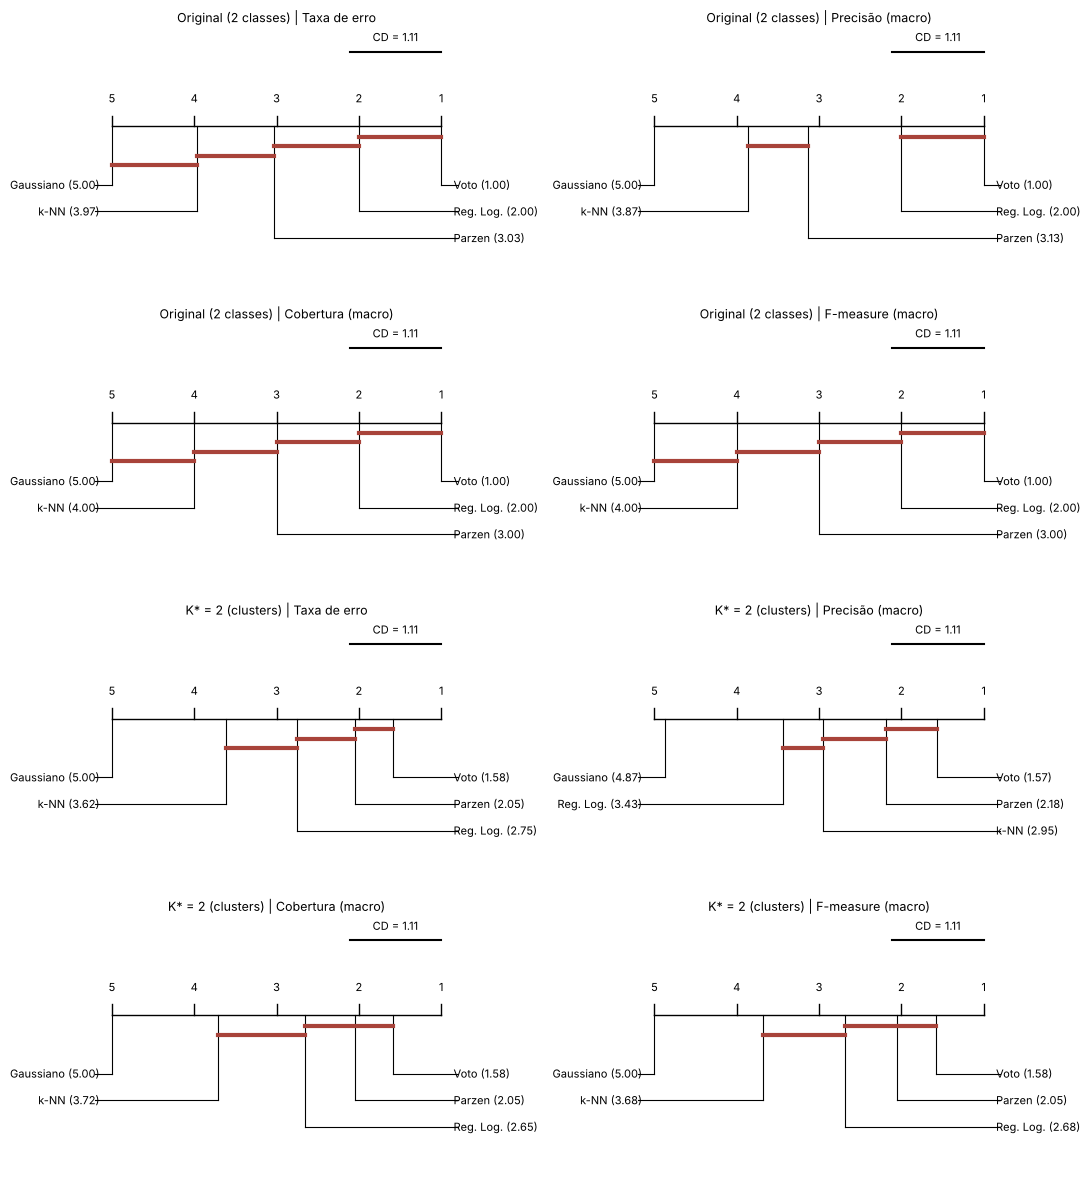

In [ ]:
figs["30rep"][0].tight_layout(); figs["30rep"][0].savefig(RESULTS / "2c_cd_diagrams_30rep.png", dpi=150)
figs["300folds"][0].tight_layout(); figs["300folds"][0].savefig(RESULTS / "2c_cd_diagrams_300folds.png", dpi=150)
figs["30rep"][0]   # diagramas de diferenca critica (blocos = 30 repeticoes)

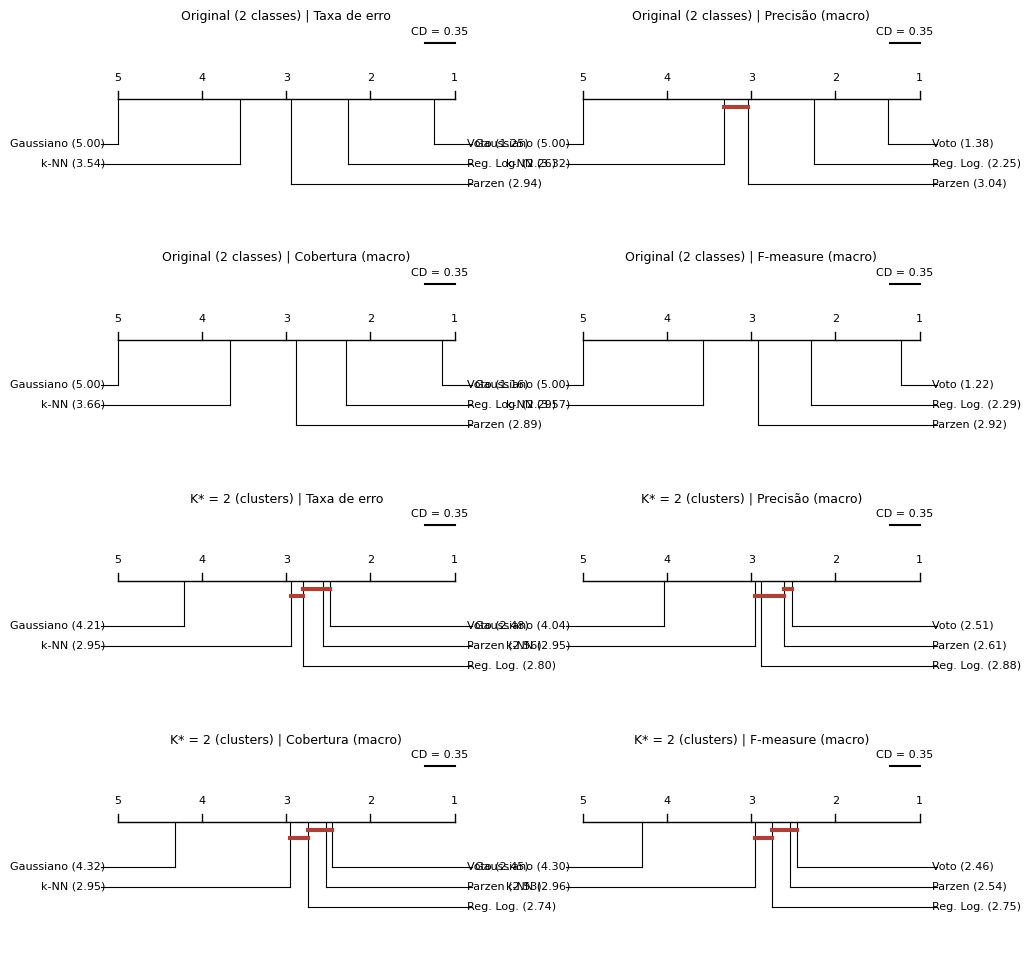

In [ ]:
figs["300folds"][0]   # sensibilidade: blocos = 300 folds

## 2d. Curvas de aprendizagem (F-measure)
Para cada fração de treino $f\in\{5\%,10\%,\dots,95\%\}$ (teste $=1-f$), amostragem estratificada do conjunto original: (1) ajuste de hiperparâmetros por CV estratificada **dentro do treino** (com $f$ pequeno a classe minoritária da versão 2 tem só 2 e-mails no treino, então usa-se `min(5, menor classe)` folds); (2) re-treino com o treino completo; (3) F-measure no **treino** (resubstituição) e no **teste**. Cada ponto é a média de `Q2_REPS_2D` partições estratificadas distintas (faixa = ±1 desvio-padrão entre repetições). F-measure macro (média das duas classes); a da classe positiva está no CSV.

In [ ]:
FRACS = np.round(np.arange(0.05, 0.951, 0.05), 2)       # 5% ... 95% (19 valores)


def tune(Xtr, ytr, c, seed):
    """CV interna estratificada; devolve o indice escolhido na grade de cada modelo (macro-F pooled)."""
    ns = int(min(5, np.bincount(ytr, minlength=c).min()))
    best = {m: 0 for m in HP_DESC}                     # fallback (so se ns < 2)
    if ns < 2:
        return best
    inner = StratifiedKFold(ns, shuffle=True, random_state=seed)
    pooled = {m: np.zeros((len(HP_DESC[m]), len(ytr)), dtype=np.int64) for m in HP_DESC}
    for itr, iva in inner.split(Xtr, ytr):
        G = all_grids(Xtr[itr], ytr[itr], Xtr[iva], c)
        for m in G:
            for j, P in enumerate(G[m]):
                pooled[m][j, iva] = P.argmax(1)
    for m in HP_DESC:
        best[m] = int(np.argmax([macro_f(ytr, pooled[m][j], c) for j in range(len(HP_DESC[m]))]))
    return best


def one_split(fi, rep, frac, X, y, c):
    rs = SEED + 1000 * rep + int(round(frac * 100))
    tr, te = train_test_split(np.arange(len(y)), train_size=frac, stratify=y, random_state=rs)
    best = tune(X[tr], y[tr], c, rs)
    sel = {m: HP_DESC[m][best[m]] for m in HP_DESC}
    Xev = np.vstack([X[te], X[tr]])                      # teste primeiro, depois o proprio treino
    G = all_grids(X[tr], y[tr], Xev, c, sel)
    post = {m: G[m][0] for m in G}
    pred = {m: post[m].argmax(1) for m in post}
    pred["vote"] = majority_vote([post[m] for m in ["gauss", "knn", "parzen", "lr"]])
    nte = len(te)
    cm_te = np.stack([conf_matrix(y[te], pred[m][:nte], c) for m in CLF])
    cm_tr = np.stack([conf_matrix(y[tr], pred[m][nte:], c) for m in CLF])
    return fi, rep, cm_tr, cm_te, np.array([best[m] for m in HP_DESC])

In [ ]:
def run_2d(version, y, reps, jobs):
    c = int(y.max() + 1)
    tasks = sorted([(fi, r, f) for fi, f in enumerate(FRACS) for r in range(reps)], key=lambda t: -t[2])
    t0 = time.time()
    res = Parallel(n_jobs=jobs)(delayed(one_split)(fi, r, f, X, y, c) for fi, r, f in tasks)
    nf = len(FRACS)
    cm_tr = np.zeros((nf, reps, len(CLF), c, c), dtype=np.int64); cm_te = np.zeros_like(cm_tr)
    hps = np.zeros((nf, reps, len(HP_DESC)), dtype=np.int64)
    for fi, r, a_tr, a_te, hp in res:
        cm_tr[fi, r], cm_te[fi, r], hps[fi, r] = a_tr, a_te, hp
    np.savez(RESULTS / f"2d_{version}.npz", cm_tr=cm_tr, cm_te=cm_te, hps=hps, fracs=FRACS, clf=np.array(CLF))
    print(f"2d/{version}: {len(tasks)} particoes em {time.time() - t0:.0f}s")

def get_2d(version):
    f = RESULTS / f"2d_{version}.npz"
    if RUN_FULL or not f.exists():
        run_2d(version, VERSIONS_Y[version], N_REPS_2D, N_JOBS)
    return np.load(f)

Z2D = {v: get_2d(v) for v in VERSIONS_Y}
{v: Z2D[v]["cm_te"].shape for v in Z2D}

2d/orig: 190 particoes em 965s
2d/kstar: 190 particoes em 863s


{'orig': (19, 10, 5, 2, 2), 'kstar': (19, 10, 5, 2, 2)}

In [ ]:
OKABE = {"gauss": "#0072B2", "knn": "#E69F00", "parzen": "#009E73", "lr": "#CC79A7", "vote": "#222222"}
CLF_NAMES = {"gauss": "Gaussiano", "knn": "k-NN", "parzen": "Parzen", "lr": "Reg. Log.", "vote": "Voto"}


def curve_table(z, fold_metrics, clf):
    """DataFrame longo: fracao, classificador, conjunto (treino/teste), media e dp de cada metrica."""
    cm = {"treino": z["cm_tr"], "teste": z["cm_te"]}
    fr = np.round(z["fracs"] * 100).astype(int)
    rows, raw = [], {}
    for split, a in cm.items():
        nf, R, K, c, _ = a.shape
        M = fold_metrics(a.reshape(nf * R, K, c, c))
        for m in ("F_macro", "F_pos", "erro"):
            raw[(split, m)] = M[m].reshape(nf, R, K)           # (fracao, repeticao, classificador)
        for i, f in enumerate(fr):
            for j, name in enumerate(clf):
                r = {"fracao_treino_pct": int(f), "classificador": name, "conjunto": split}
                for m in ("F_macro", "F_pos", "erro"):
                    x = raw[(split, m)][i, :, j]
                    r[m] = x.mean()
                    r[m + "_sd"] = x.std(ddof=1)
                rows.append(r)
    return pd.DataFrame(rows), raw


def plot_curves(tab, version_name, metric="F_macro", ylabel="F-measure (macro)", fname=None):
    clfs = list(CLF_NAMES)
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
    for ax, name in zip(axes.ravel(), clfs + ["comparacao"]):
        if name == "comparacao":
            for c in clfs:
                t = tab[(tab.classificador == c) & (tab.conjunto == "teste")]
                ax.plot(t.fracao_treino_pct, t[metric], color=OKABE[c], lw=1.8, label=CLF_NAMES[c])
            ax.set_title("Teste: comparação", fontsize=10)
            ax.legend(fontsize=8, frameon=False, loc="lower right")
        else:
            for split, ls in (("treino", "--"), ("teste", "-")):
                t = tab[(tab.classificador == name) & (tab.conjunto == split)]
                ax.plot(t.fracao_treino_pct, t[metric], ls, color=OKABE[name], lw=1.8, label=split)
                ax.fill_between(t.fracao_treino_pct, t[metric] - t[metric + "_sd"],
                                t[metric] + t[metric + "_sd"], color=OKABE[name], alpha=0.15, lw=0)
            ax.set_title(CLF_NAMES[name], fontsize=10)
            ax.legend(fontsize=8, frameon=False, loc="lower right")
        ax.grid(alpha=0.25)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    for ax in axes[1]:
        ax.set_xlabel("% do conjunto usado no treino")
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    ymin = max(0.0, float(tab[metric].min()) - 0.05)
    axes[0, 0].set_ylim(ymin, 1.02)
    fig.suptitle(f"Curvas de aprendizagem — {version_name}", fontsize=12)
    fig.tight_layout()
    if fname:
        fig.savefig(fname, dpi=150)
    return fig

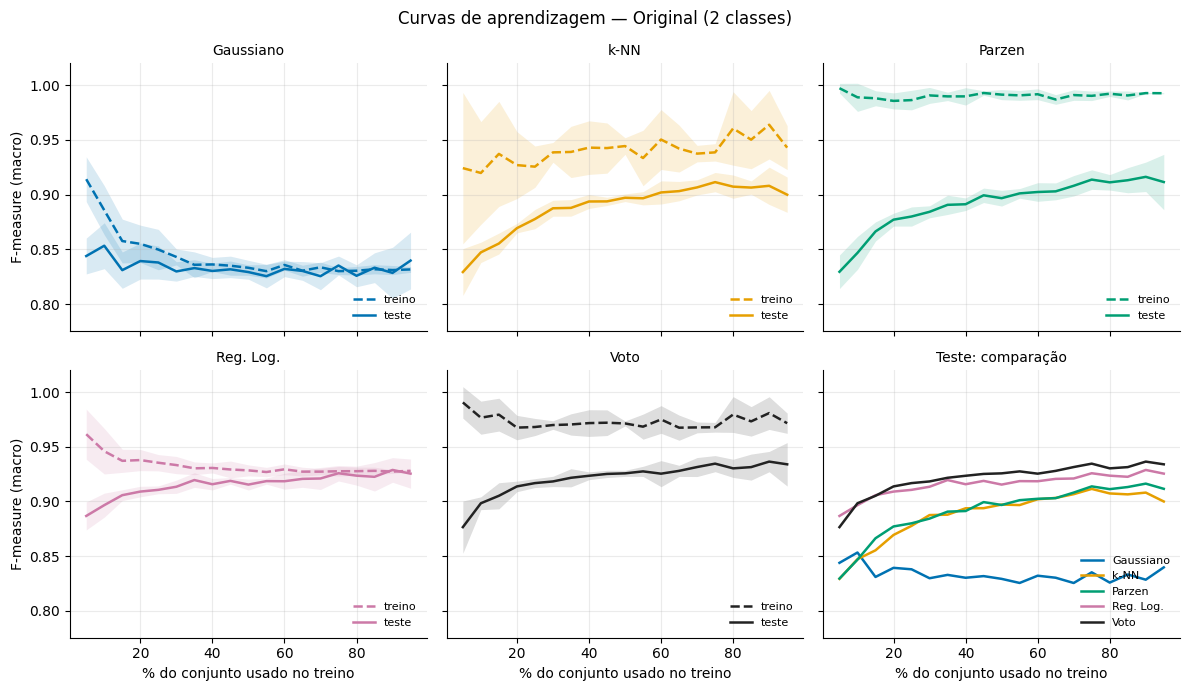

In [ ]:
TAB_2D = {}
for ver, z in Z2D.items():
    TAB_2D[ver], _ = curve_table(z, fold_metrics, CLF)
    TAB_2D[ver].assign(versao=ver).to_csv(RESULTS / f"2d_curvas_{ver}.csv", index=False)
fig = plot_curves(TAB_2D["orig"], VERSIONS["orig"], fname=RESULTS / "2d_curvas_orig.png"); plt.show()

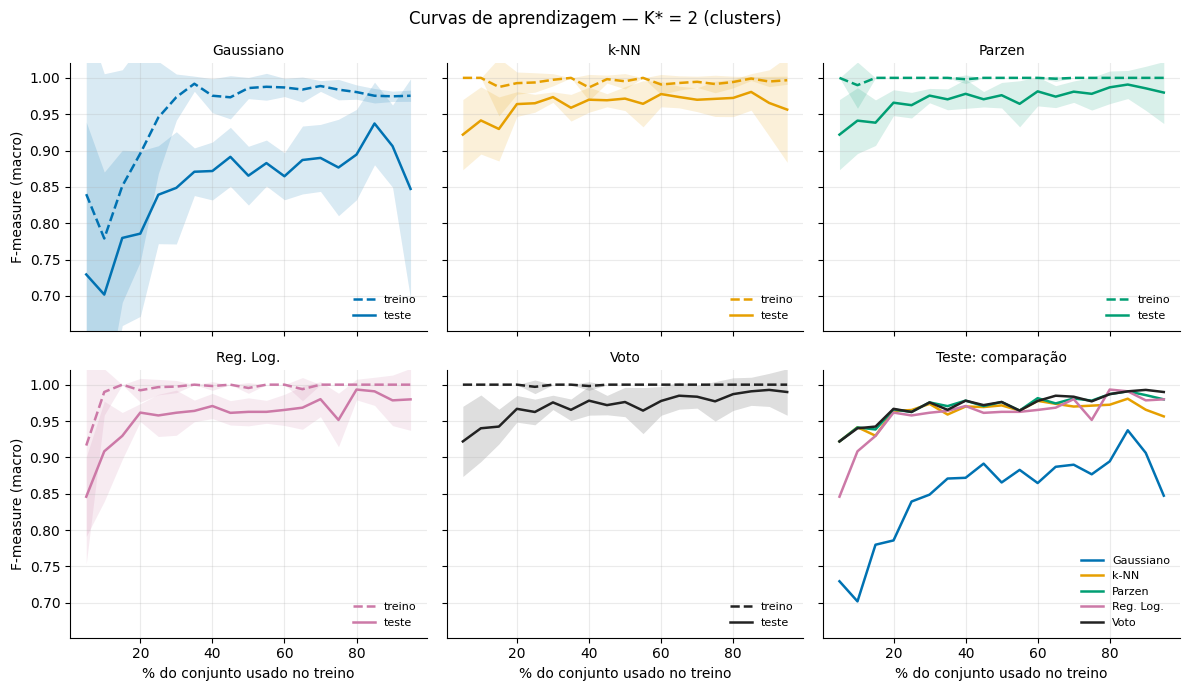

In [ ]:
fig = plot_curves(TAB_2D["kstar"], VERSIONS["kstar"], fname=RESULTS / "2d_curvas_kstar.png"); plt.show()

In [ ]:
# F-measure (macro), media entre repeticoes: treino x teste em algumas fracoes
for ver in TAB_2D:
    t = TAB_2D[ver]; t = t[t.fracao_treino_pct.isin([5, 25, 50, 75, 95])]
    pv = t.pivot_table(index="classificador", columns=["fracao_treino_pct", "conjunto"], values="F_macro").loc[CLF]
    print(f"\n== {VERSIONS[ver]}: F-measure macro (treino / teste) =="); display(pv.round(3))


== Original (2 classes): F-measure macro (treino / teste) ==


fracao_treino_pct     5             25            50            75            95       
conjunto           teste treino  teste treino  teste treino  teste treino  teste treino
classificador                                                                          
gauss              0.844  0.914  0.838  0.850  0.829  0.833  0.835  0.830  0.840  0.832
knn                0.829  0.924  0.878  0.926  0.897  0.944  0.911  0.939  0.900  0.943
parzen             0.830  0.997  0.880  0.986  0.897  0.991  0.914  0.990  0.912  0.993
lr                 0.887  0.961  0.911  0.935  0.915  0.928  0.926  0.928  0.925  0.928
vote               0.877  0.990  0.917  0.968  0.926  0.971  0.935  0.968  0.934  0.971


== K* = 2 (clusters): F-measure macro (treino / teste) ==


fracao_treino_pct     5             25            50            75            95       
conjunto           teste treino  teste treino  teste treino  teste treino  teste treino
classificador                                                                          
gauss              0.730  0.840  0.839  0.945  0.865  0.986  0.877  0.984  0.847  0.975
knn                0.922  1.000  0.965  0.994  0.971  0.995  0.971  0.992  0.956  0.997
parzen             0.922  1.000  0.962  1.000  0.976  1.000  0.978  1.000  0.980  1.000
lr                 0.846  0.916  0.958  0.997  0.963  0.995  0.951  1.000  0.980  1.000
vote               0.922  1.000  0.962  0.997  0.976  1.000  0.977  1.000  0.990  1.000

### Comentários sobre as curvas de aprendizagem (2d)

Lê-se cada painel pela distância entre as curvas de treino (tracejada, resubstituição) e de teste (contínua) e pelo que ocorre com ela quando o treino cresce. Curvas que **convergem** num patamar abaixo de 1 indicam um classificador limitado pelo viés (a família de modelos não representa bem o problema), e mais dados não ajudam. Curvas que **mantêm uma folga grande** indicam limitação por variância, e a curva de teste ainda tende a subir com mais dados.

**Versão original (spam × não-spam).**
- *Bayesiano gaussiano:* é o único cujo desempenho de teste praticamente não depende do tamanho do treino. A curva de treino cai até encontrar a de teste ainda com poucos dados, e as duas ficam coladas num patamar baixo. É o padrão típico de viés alto, coerente com a suposição gaussiana ser inadequada para variáveis esparsas e de cauda pesada (frequências de palavras e de caracteres).
- *k-vizinhos e Parzen:* têm viés baixo e variância alta. O teste sobe de forma contínua até cerca de 75–90% do treino, sem estabilizar claramente, e a folga em relação ao treino permanece grande. A F-measure de treino do Parzen é quase 1 porque, na resubstituição, cada ponto contribui com o próprio kernel (a janela escolhida é pequena); esse valor não deve ser lido como desempenho. A forma das curvas sugere que mais dados ainda beneficiariam os dois, em particular o Parzen.
- *Regressão logística:* treino e teste convergem para um patamar comum já por volta de metade do conjunto, com folga praticamente nula. É o classificador mais estável e o melhor dos quatro individuais com treinos pequenos, mas satura, o que sugere limitação de capacidade (fronteira linear).
- *Voto majoritário:* segue o melhor dos componentes com treinos muito pequenos e passa a superá-los a partir de frações moderadas, mantendo a maior F-measure de teste até o fim. Sua folga treino–teste, porém, é a de seus componentes não lineares.
- *Comparação:* com 5% do conjunto (cerca de 230 e-mails) a ordem entre classificadores difere da ordem com mais dados, e k-NN e Parzen só superam o gaussiano com frações maiores. A diferença entre os métodos nas frações grandes é pequena frente à variabilidade entre repetições, o que está de acordo com os resultados dos itens 2b e 2c.

**Versão $K^*=2$ (clusters).**
- A tarefa é muito mais fácil: os 34 e-mails do cluster pequeno são pontos extremos, e k-NN, Parzen, regressão logística e voto atingem F-measure alta com poucos exemplos desse cluster no treino (apenas 2 com 5% dos dados). As curvas de treino ficam praticamente em 1.
- O gaussiano é o pior e o mais instável. Com poucos exemplos da classe minoritária a covariância é singular (rank menor que a dimensão), e a regularização por $\lambda$ não resolve bem a estimação; a curva é irregular e tem desvio-padrão grande.
- **Cautela:** a classe minoritária tem 34 e-mails, então o conjunto de teste tem poucos exemplos dela (cerca de 2 com 95% de treino). Um único erro altera muito a F-measure, e por isso as faixas de desvio-padrão são largas e as oscilações nas frações grandes (inclusive a queda do gaussiano e do k-NN no final) refletem sobretudo ruído de amostragem de teste, não degradação real com mais dados. As comparações entre k-NN, Parzen, regressão logística e voto nesta versão não devem ser interpretadas como diferenças reais, em linha com o resultado do Nemenyi na 2c.

**Limitações.** Cada ponto é a média de 10 partições estratificadas por fração, e os conjuntos de treino de frações diferentes não são aninhados. A F-measure de treino é de resubstituição e, para métodos baseados em memória (k-NN, Parzen), é otimista por construção.